# Grid Convergence and Discretization Uncertainty
### Manufactured-solution verification, Richardson extrapolation, and GCI

**Learning goal:** Demonstrate second-order grid convergence of a 1D Poisson solver, estimate uncertainty in a scalar output without using the exact answer, and then audit that estimate against the known solution.

This is a synthetic, dimensionless verification problem. A converged algebraic residual can coexist with substantial discretization error.

**Targets:** Last two error-based orders in [1.9, 2.1]; decreasing field errors; finest-grid relative residual below $10^{-10}$; fine-grid GCI below 0.1%; and comparison of the GCI estimate with the actual scalar error.

Use a Python kernel with NumPy, SciPy, and Matplotlib.

**Notation:** $N$ is the number of intervals, $h=1/N$, $u_i$ the numerical nodal solution, $u_*(x)$ the reference, and $e_i=u_i-u_*(x_i)$. For three-grid estimates, subscripts 1, 2, 3 always mean fine, medium, coarse.


## 1. Governing model and reference solution

Solve the steady, dimensionless diffusion problem
$$-u''(x)=f(x),\quad 0<x<1,\qquad u(0)=u(1)=0.$$
The diffusion coefficient is one. Choose the manufactured solution
$$u_*(x)=\sin(\pi x).$$

**Task:** Differentiate $u_*$ analytically and derive $f$ before assembling any discrete equations. Record your derivation here. Do not construct $f$ by applying the discrete operator to sampled $u_*$: that would hide truncation error.

Interpret $u$ as a scaled temperature or potential. All quantities in this notebook are dimensionless. The scalar engineering output is $Q_h=u_h(0.5)$; all specified meshes contain that node. Derive $Q_*=u_*(0.5)$ independently.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve
from time import perf_counter
from IPython.display import Markdown, display

N_VALUES = (16, 32, 64, 128)
FS = 1.25
L = 1.0
parameters = {
    'k': 1.0,
    'source': lambda x: np.pi**2 * np.sin(np.pi * x),
    'u0': 0.0,
    'uL': 0.0,
    'L': L,
    'N_values': N_VALUES,
    'FS': FS,
}

## 2. Discretization and conditions

Use a uniform nodal mesh $x_i=ih$ with $N+1$ nodes and $N-1$ interior unknowns. Approximate the second derivative with the centered three-point stencil; derive the signs and the $h^{-2}$ scaling for the equation $-u''=f$.

**Tasks:** Assemble a sparse tridiagonal interior matrix, account for Dirichlet boundary values, solve with `spsolve`, and reconstruct the full nodal vector. Return the interior matrix and right-hand side for residual diagnostics. Avoid dense matrices.

Explain why this interior matrix is symmetric positive definite and why its condition number grows under refinement. This is a steady elliptic solve: no explicit time-step CFL restriction applies.

The API should separate assembly, solve, and diagnostics sufficiently to replace the linear solver later. A helper function for assembly is encouraged. Time assembly and solve separately if practical; one short timing is descriptive, not a scaling benchmark.

In [2]:
def u_star(x):
    """Return the exact solution u* at x."""
    return np.sin(np.pi * x)

def solve_problem(parameters):
    """Return a dict keyed by N with x, u, A, b, assembly_s, solve_s, and Q.

    N is the number of intervals; A and b contain the N-1 interior DOFs.
    parameters holds boundary values and the source callable.
    """
    L = parameters['L']
    k = parameters['k']
    results = {}
    for N in parameters['N_values']:
        h = L / N
        x = np.linspace(0, L, N + 1)

        t0 = perf_counter()
        n_int = N - 1
        main_diag = np.full(n_int, 2.0 * k / h**2)
        off_diag = np.full(n_int - 1, -k / h**2)
        A = diags([off_diag, main_diag, off_diag], offsets=[-1, 0, 1], format='csr')
        b = parameters['source'](x[1:-1])
        assembly_s = perf_counter() - t0

        t0 = perf_counter()
        u_interior = spsolve(A, b)
        solve_s = perf_counter() - t0

        u = np.concatenate(([parameters['u0']], u_interior, [parameters['uL']]))
        residual = A @ u_interior - b
        R = np.linalg.norm(residual) / np.linalg.norm(b)

        i_mid = N // 2  # N is a power of two, so x=0.5 is always a node
        assert np.isclose(x[i_mid], 0.5)

        results[N] = {
            'x': x,
            'u': u,
            'A': A,
            'b': b,
            'assembly_s': assembly_s,
            'solve_s': solve_s,
            'R': R,
            'Q': u[i_mid],
        }
    return results

results = solve_problem(parameters)
Q_star = u_star(0.5)


## 3. Error measures and expected behavior

Compute
$$E_2=\sqrt{h\sum_{i=1}^{N-1}e_i^2},\quad E_\infty=\max_i|e_i|,
\quad R=\frac{\|b-Au_{\rm interior}\|_2}{\|b\|_2}.$$
For adjacent meshes with $r=2$, estimate $p_E=\log(E_{\rm coarse}/E_{\rm fine})/\log r$. Expect approximately second-order field error for this smooth problem.

For each consecutive three-grid set, compute $\Delta_{21}=Q_2-Q_1$ and $\Delta_{32}=Q_3-Q_2$. First check they are nonzero and have the same sign. For monotone convergence with constant refinement ratio, use
$$p_Q=\frac{\log|\Delta_{32}/\Delta_{21}|}{\log r},\qquad
Q_{\rm ext}=Q_1+\frac{Q_1-Q_2}{r^{p_Q}-1}.$$
Estimate the fine-grid fractional GCI as
$$g_{12}=\frac{F_s |(Q_1-Q_2)/Q_1|}{r^{p_Q}-1},\qquad F_s=1.25.$$
Report $100g_{12}$ in percent and $\delta Q_{\rm GCI}=g_{12}|Q_1|$ in output units. Compare it with $|Q_1-Q_*|$ only after the estimate is formed. Do not substitute the known theoretical order into your primary GCI calculation.

For an asymptotic diagnostic compute $g_{23}$ with the same $p_Q$ and $F_s$, normalized by $Q_2$, then inspect $g_{23}/(r^{p_Q}g_{12})$. It should be near one, but this is only a consistency check: fitted three-grid ratios are not independent proof of asymptotic convergence. Compare both triplets and the exact-error trend.

Reject or flag zero differences, oscillatory convergence, $p_Q\leq0$, or tiny $Q_1$ instead of producing a misleading GCI. Residuals measure algebraic consistency; solution error also depends on conditioning and discretization. GCI is an estimate, not a guaranteed bound or a statistical confidence interval.

In [3]:
def compute_errors(results):
    """Compute field error norms and observed order for each mesh."""
    for N in results:
        x = results[N]['x']
        u = results[N]['u']
        u_exact = u_star(x)
        h = L / N
        e = u - u_exact
        E2 = np.sqrt(h * np.sum(e[1:-1]**2))
        Einf = np.max(np.abs(e))
        results[N]['E2'] = E2
        results[N]['Einf'] = Einf
    # Observed order from adjacent meshes with refinement ratio r=2.
    N_sorted = sorted(results.keys())
    for i in range(1, len(N_sorted)):
        N_coarse = N_sorted[i - 1]
        N_fine = N_sorted[i]
        E2_coarse = results[N_coarse]['E2']
        E2_fine = results[N_fine]['E2']
        results[N_fine]['p_E2'] = np.log(E2_coarse / E2_fine) / np.log(2)
    return results

results = compute_errors(results)

def three_grid_diagnostic(results, N_coarse, N_medium, N_fine, r=2, Fs=1.25):
    """Richardson extrapolation and GCI for one fine/medium/coarse triplet.

    Subscripts 1, 2, 3 denote fine, medium, coarse, matching the write-up.
    """
    Q1, Q2, Q3 = results[N_fine]['Q'], results[N_medium]['Q'], results[N_coarse]['Q']
    d21 = Q2 - Q1
    d32 = Q3 - Q2
    monotone = (d21 != 0) and (np.sign(d21) == np.sign(d32))
    if not monotone:
        return {'monotone': False, 'd21': d21, 'd32': d32}

    p_Q = np.log(np.abs(d32 / d21)) / np.log(r)
    Q_ext = Q1 + (Q1 - Q2) / (r**p_Q - 1)
    g12 = Fs * np.abs((Q1 - Q2) / Q1) / (r**p_Q - 1)
    g23 = Fs * np.abs((Q2 - Q3) / Q2) / (r**p_Q - 1)
    delta_Q_gci = g12 * np.abs(Q1)
    actual_error = np.abs(Q1 - Q_star)
    asymptotic_ratio = g23 / (r**p_Q * g12)

    return {
        'monotone': True,
        'p_Q': p_Q,
        'Q_ext': Q_ext,
        'g12_pct': 100 * g12,
        'delta_Q_gci': delta_Q_gci,
        'actual_error': actual_error,
        'asymptotic_ratio': asymptotic_ratio,
    }

gci_results = {
    (16, 32, 64): three_grid_diagnostic(results, 16, 32, 64),
    (32, 64, 128): three_grid_diagnostic(results, 32, 64, 128),
}


## 4. Results and convergence

**Deliverable 1:** A mesh table with N, h, E2, Einf, observed E2 order, residual, Q, matrix nnz, assembly time, and solve time (seconds).

**Deliverable 2:** A three-grid table with fine/medium/coarse N, p_Q, Q_ext, fine GCI (%), absolute GCI estimate, actual fine-grid scalar error, and asymptotic ratio.

Explain whether the uncertainty estimate covers the actual error in this particular example. Do not generalize that result into a universal guarantee. Distinguish mesh intervals, nodal values, and interior degrees of freedom.

In [4]:
table = ['| N | h | E2 | Einf | p_E2 | Residual R | nnz(A) | assembly (s) | solve (s) |',
         '|---|---|---|---|---|---|---|---|---|']
for N in sorted(results.keys()):
    h = L / N
    r = results[N]
    p_E2 = r.get('p_E2', '-')
    p_E2_str = f'{p_E2:.4f}' if isinstance(p_E2, float) else p_E2
    table.append(f"| {N} | {h:.5f} | {r['E2']:.5e} | {r['Einf']:.5e} | {p_E2_str} "
                 f"| {r['R']:.3e} | {r['A'].nnz} | {r['assembly_s']:.2e} | {r['solve_s']:.2e} |")
display(Markdown('\n'.join(table)))

table_gci = ['| Coarse | Medium | Fine | p_Q | Q_ext | Fine GCI (%) | abs GCI | actual |Q1-Q*| | g23/(r^p g12) |',
             '|---|---|---|---|---|---|---|---|---|']
for (N_coarse, N_medium, N_fine), diag in gci_results.items():
    table_gci.append(
        f"| {N_coarse} | {N_medium} | {N_fine} | {diag['p_Q']:.4f} | {diag['Q_ext']:.8f} "
        f"| {diag['g12_pct']:.5f} | {diag['delta_Q_gci']:.3e} | {diag['actual_error']:.3e} "
        f"| {diag['asymptotic_ratio']:.4f} |")
display(Markdown('\n'.join(table_gci)))


| N | h | E2 | Einf | p_E2 | Residual R | nnz(A) | assembly (s) | solve (s) |
|---|---|---|---|---|---|---|---|---|
| 16 | 0.06250 | 2.27615e-03 | 3.21896e-03 | - | 3.832e-15 | 43 | 2.21e-04 | 7.48e-05 |
| 32 | 0.03125 | 5.68215e-04 | 8.03578e-04 | 2.0021 | 9.928e-15 | 91 | 9.08e-05 | 3.85e-05 |
| 64 | 0.01562 | 1.42002e-04 | 2.00822e-04 | 2.0005 | 4.855e-14 | 187 | 6.68e-05 | 4.29e-05 |
| 128 | 0.00781 | 3.54974e-05 | 5.02009e-05 | 2.0001 | 2.114e-13 | 379 | 5.65e-05 | 5.18e-05 |

| Coarse | Medium | Fine | p_Q | Q_ext | Fine GCI (%) | abs GCI | actual |Q1-Q*| | g23/(r^p g12) |
|---|---|---|---|---|---|---|---|---|
| 16 | 32 | 64 | 2.0026 | 1.00000039 | 0.02505 | 2.505e-04 | 2.008e-04 | 0.9994 |
| 32 | 64 | 128 | 2.0007 | 1.00000002 | 0.00627 | 6.272e-05 | 5.020e-05 | 0.9998 |

## 5. Solution and diagnostic plots

Create three panels: (1) finest-grid solution and a densely sampled exact curve; (2) log-log E2 and Einf versus h, with a reference slope of two anchored to an observed point; (3) scalar Q versus h^2 with the exact and extrapolated values indicated.

Label every axis as dimensionless where appropriate. A visually overlapping solution curve is insufficient evidence of accuracy. Use the error plot and scalar table to quantify it.

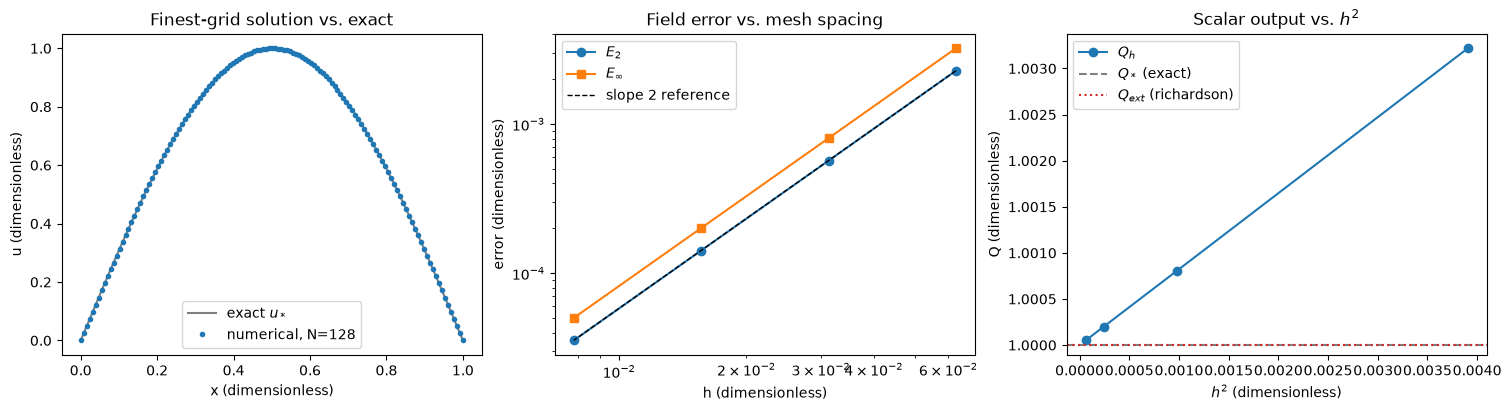

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')

N_fine_mesh = max(results.keys())
x_fine = results[N_fine_mesh]['x']
x_dense = np.linspace(0, L, 400)
axes[0].plot(x_dense, u_star(x_dense), label='exact $u_*$', color='tab:gray', lw=1.5)
axes[0].plot(x_fine, results[N_fine_mesh]['u'], 'o', ms=3, label=f'numerical, N={N_fine_mesh}', color='tab:blue')
axes[0].set(xlabel='x (dimensionless)', ylabel='u (dimensionless)', title='Finest-grid solution vs. exact')
axes[0].legend()

N_values = sorted(results.keys())
h_values = [L / N for N in N_values]
E2_values = [results[N]['E2'] for N in N_values]
Einf_values = [results[N]['Einf'] for N in N_values]
axes[1].loglog(h_values, E2_values, 'o-', label='$E_2$')
axes[1].loglog(h_values, Einf_values, 's-', label='$E_\\infty$')
h_ref = np.array([h_values[0], h_values[-1]])
axes[1].loglog(h_ref, E2_values[0] * (h_ref / h_values[0])**2, 'k--', lw=1, label='slope 2 reference')
axes[1].set(xlabel='h (dimensionless)', ylabel='error (dimensionless)', title='Field error vs. mesh spacing')
axes[1].legend()

Q_values = [results[N]['Q'] for N in N_values]
h2_values = [h**2 for h in h_values]
axes[2].plot(h2_values, Q_values, 'o-', label='$Q_h$')
axes[2].axhline(Q_star, color='tab:gray', ls='--', label='$Q_*$ (exact)')
Q_ext_fine = gci_results[(32, 64, 128)]['Q_ext']
axes[2].axhline(Q_ext_fine, color='tab:red', ls=':', label='$Q_{ext}$ (richardson)')
axes[2].set(xlabel='$h^2$ (dimensionless)', ylabel='Q (dimensionless)', title='Scalar output vs. $h^2$')
axes[2].legend()
plt.show()


## 6. Automatic checks

Assert: finite values; correct array sizes; exact imposed boundary values; reflection symmetry to absolute tolerance 1e-10; decreasing E2 and Einf; last two p_E values in [1.9, 2.1]; residual below 1e-10 on every mesh; and fine GCI below 0.1% for the (128, 64, 32) triplet.

Verify the matrix is symmetric and has at most 3(N-1) nonzero entries. Check the source and exact solution are evaluated independently of assembly. Discuss the observed GCI coverage instead of asserting universal coverage. If a check fails, investigate signs, h scaling, refinement indexing, boundary treatment, and roundoff before weakening the target.

In [6]:
def assert_results(results):
    """Assert solver, error, and convergence properties for each mesh."""
    N_sorted = sorted(results.keys())
    for N in N_sorted:
        r = results[N]
        x, u, A, b = r['x'], r['u'], r['A'], r['b']
        assert np.all(np.isfinite(u)) and np.all(np.isfinite(b))
        assert len(x) == N + 1 and len(u) == N + 1
        assert A.shape == (N - 1, N - 1)
        assert b.shape == (N - 1,)
        assert A.nnz <= 3 * (N - 1), f"A has more nonzeros than a tridiagonal matrix allows for N={N}"
        np.testing.assert_allclose((A - A.T).toarray(), 0.0, atol=1e-12)
        assert u[0] == parameters['u0'] and u[-1] == parameters['uL']
        np.testing.assert_allclose(u, u[::-1], atol=1e-10), f"Reflection symmetry failed for N={N}"
        assert r['R'] < 1e-10, f"Relative residual too large for N={N}: {r['R']:.3e}"

    E2_values = [results[N]['E2'] for N in N_sorted]
    Einf_values = [results[N]['Einf'] for N in N_sorted]
    assert all(E2_values[i] > E2_values[i + 1] for i in range(len(E2_values) - 1)), "E2 must decrease under refinement"
    assert all(Einf_values[i] > Einf_values[i + 1] for i in range(len(Einf_values) - 1)), "Einf must decrease under refinement"

    p_E2_values = [results[N]['p_E2'] for N in N_sorted[1:]]
    assert all(1.9 <= p <= 2.1 for p in p_E2_values[-2:]), f"Last two p_E2 values out of [1.9, 2.1]: {p_E2_values[-2:]}"

def assert_gci(gci_results):
    """Assert the three-grid Richardson/GCI diagnostics are well formed."""
    for (N_coarse, N_medium, N_fine), diag in gci_results.items():
        assert diag['monotone'], f"Non-monotone convergence for triplet ({N_coarse}, {N_medium}, {N_fine})"
        assert diag['p_Q'] > 0, f"Non-positive observed order for triplet ({N_coarse}, {N_medium}, {N_fine})"
    fine_gci = gci_results[(32, 64, 128)]
    assert fine_gci['g12_pct'] < 0.1, f"Fine-grid GCI {fine_gci['g12_pct']:.4f}% exceeds 0.1% target"

assert_results(results)
assert_gci(gci_results)
print("PASS: residuals below 1e-10, E2/Einf decreasing, last two p_E2 in [1.9, 2.1], "
      "and fine-grid GCI below 0.1% for the (32, 64, 128) triplet.")


PASS: residuals below 1e-10, E2/Einf decreasing, last two p_E2 in [1.9, 2.1], and fine-grid GCI below 0.1% for the (32, 64, 128) triplet.


## 7. Discussion and next steps

### Further work

**Optional stretch:** Replace the direct solve with conjugate gradients and sweep relative tolerances 1e-2, 1e-4, 1e-6, 1e-10. Use a non-eigenvector forcing from a separately derived manufactured solution u_*(x)=exp(x)-1-(exp(1)-1)x. Predict when algebraic error will mask grid convergence, then compare against the direct-solve baseline. The primary sine forcing can make CG converge unusually quickly, so it is unsuitable for a meaningful tolerance experiment.

### References

- **Technical paper:** I. B. Celik, U. Ghia, P. J. Roache, C. J. Freitas, H. Coleman, and P. E. Raad (2008), *Procedure for Estimation and Reporting of Uncertainty Due to Discretization in CFD Applications*, Journal of Fluids Engineering 130(7), 078001. [DOI](https://doi.org/10.1115/1.2960953). Full publisher text may require institutional access; this is a foundational reading, not a new paper announcement.
- **Dedicated project reference:** NASA Glenn / NPARC Alliance, [Examining Spatial (Grid) Convergence](https://www.grc.nasa.gov/www/wind/valid/tutorial/spatconv.html). Use its discussion of observed order, Richardson extrapolation, and GCI. Publicly accessible; last updated February 10, 2021.
